# 01 — Exploratory data analysis

What the two datasets look like after cleaning, before any model is trained.

1. MTSamples cleaning funnel
2. Class distribution per split
3. Report length per class
4. Length in BERT tokens (how many reports exceed 512?)
5. Operative reports per class (could the model learn report type instead of specialty?)
6. MACCROBAT entities

Run `python -m src.data` first: this notebook only reads the saved files.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

# Silence harmless environment warnings (Windows symlinks, progress bars, HF login)
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")

# Make "src" importable whether the notebook runs from the project root or notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data import PROCESSED_DIR, is_operative, load_maccrobat_split, load_mtsamples_splits
from src.utils import load_config

config = load_config(ROOT / "configs" / "data.yaml")
splits = load_mtsamples_splits()
df = pd.concat([part.assign(split=name) for name, part in splits.items()], ignore_index=True)
CLASS_ORDER = df["label"].value_counts().index  # largest class first
print(len(df), "reports")

1282 reports


## 1. MTSamples cleaning funnel

In [2]:
funnel = json.loads((PROCESSED_DIR / "mtsamples" / "funnel.json").read_text())
steps = {
    "removed_empty": "empty transcription",
    "removed_duplicates": "duplicate rows (same report, several labels)",
    "removed_too_short": f"too short (< {config['mtsamples']['min_words']} words, truncated scrape)",
    "removed_catch_all_only": "only catch-all labels (Surgery, Consult, ...)",
    "removed_multi_specialty": "2+ specialties (ambiguous)",
    "removed_other_specialty": "single specialty, not one of our 8",
}
remaining = funnel["raw_rows"]
rows = [("raw rows", "", remaining)]
for key, description in steps.items():
    remaining -= funnel[key]
    rows.append((description, funnel[key], remaining))
assert remaining == funnel["kept"]
pd.DataFrame(rows, columns=["step", "removed", "remaining"])

,step,removed,remaining
0,raw rows,,4999
1,empty transcription,33,4966
2,"duplicate rows (same report, several labels)",2609,2357
3,"too short (< 50 words, truncated scrape)",41,2316
4,"only catch-all labels (Surgery, Consult, ...)",292,2024
5,2+ specialties (ambiguous),308,1716
6,"single specialty, not one of our 8",434,1282


## 2. Class distribution per split

The split is stratified, so every split has the same class proportions.

In [3]:
counts = pd.crosstab(df["label"], df["split"], margins=True, margins_name="total")
counts = counts.loc[list(CLASS_ORDER) + ["total"], ["train", "val", "test", "total"]]
counts["% of total"] = (100 * counts["total"] / len(df)).round(1)
counts

split,train,val,test,total,% of total
label,,,,,
Cardiovascular / Pulmonary,233,50,50,333,26.0
Orthopedic,153,33,33,219,17.1
Gastroenterology,129,27,28,184,14.4
Obstetrics / Gynecology,98,21,21,140,10.9
Urology,92,19,20,131,10.2
Neurology,86,19,18,123,9.6
ENT - Otolaryngology,55,12,12,79,6.2
Ophthalmology,51,11,11,73,5.7
total,897,192,193,1282,100.0


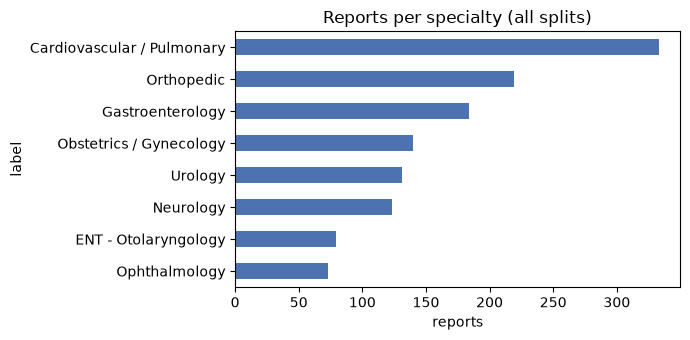

In [4]:
ax = counts.drop("total")["total"].plot.barh(figsize=(7, 3.5), color="#4C72B0")
ax.invert_yaxis()
ax.set_xlabel("reports")
ax.set_title("Reports per specialty (all splits)")
plt.tight_layout()

## 3. Report length per class (words)

In [5]:
df["n_words"] = df["text"].str.split().str.len()
df.groupby("label")["n_words"].describe()[["min", "25%", "50%", "75%", "max"]].loc[CLASS_ORDER].astype(int)

,min,25%,50%,75%,max
label,,,,,
Cardiovascular / Pulmonary,52,206,355,592,1593
Orthopedic,70,326,513,751,2019
Gastroenterology,61,207,307,474,1145
Obstetrics / Gynecology,54,261,438,658,1566
Urology,90,212,355,547,2008
Neurology,66,325,450,647,2460
ENT - Otolaryngology,78,213,331,587,1361
Ophthalmology,57,218,335,441,833


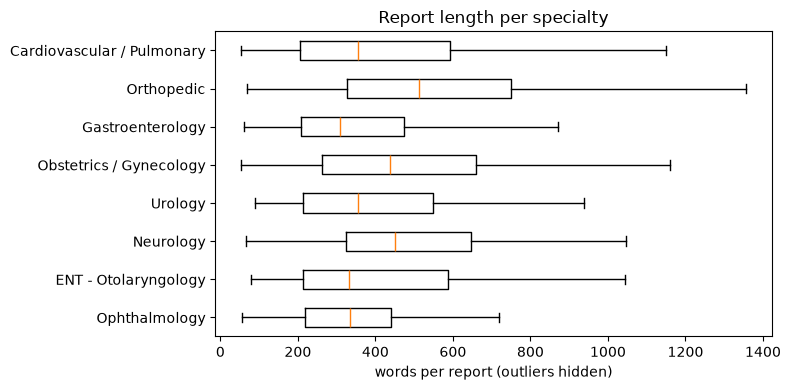

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([df.loc[df["label"] == c, "n_words"] for c in CLASS_ORDER], orientation="horizontal", showfliers=False)
ax.set_yticks(range(1, len(CLASS_ORDER) + 1), CLASS_ORDER)
ax.invert_yaxis()
ax.set_xlabel("words per report (outliers hidden)")
ax.set_title("Report length per specialty")
plt.tight_layout()

## 4. Length in BERT tokens

BERT reads at most 512 tokens (including the special [CLS] and [SEP] tokens).
Longer reports are truncated: the model only sees the beginning.
We count tokens with the exact tokenizer used for fine-tuning.

In [7]:
from transformers import AutoTokenizer
from transformers.utils import logging

logging.set_verbosity_error()  # hide the "sequence longer than 512" warning: we measure it on purpose
eda = config["eda"]
tokenizer = AutoTokenizer.from_pretrained(eda["tokenizer"], revision=eda["tokenizer_revision"])
df["n_tokens"] = [len(ids) for ids in tokenizer(df["text"].tolist())["input_ids"]]

max_tokens = eda["max_tokens"]
over = df["n_tokens"] > max_tokens
lost = (df["n_tokens"] - max_tokens).clip(lower=0).sum() / df["n_tokens"].sum()
print(f"Reports longer than {max_tokens} tokens: {over.sum()} / {len(df)} ({100 * over.mean():.1f}%)")
print(f"Median length: {df['n_tokens'].median():.0f} tokens")
print(f"Share of all tokens cut off by truncation: {100 * lost:.1f}%")

Reports longer than 512 tokens: 802 / 1282 (62.6%)
Median length: 653 tokens
Share of all tokens cut off by truncation: 40.0%


In [8]:
per_class = df.groupby("label").agg(
    reports=("n_tokens", "size"),
    median_tokens=("n_tokens", "median"),
    over_512=("n_tokens", lambda n: (n > max_tokens).sum()),
)
per_class["% over 512"] = (100 * per_class["over_512"] / per_class["reports"]).round(1)
per_class.loc[CLASS_ORDER].astype({"median_tokens": int})

,reports,median_tokens,over_512,% over 512
label,,,,
Cardiovascular / Pulmonary,333,653,199,59.8
Orthopedic,219,777,169,77.2
Gastroenterology,184,539,94,51.1
Obstetrics / Gynecology,140,732,88,62.9
Urology,131,561,74,56.5
Neurology,123,820,98,79.7
ENT - Otolaryngology,79,568,43,54.4
Ophthalmology,73,524,37,50.7


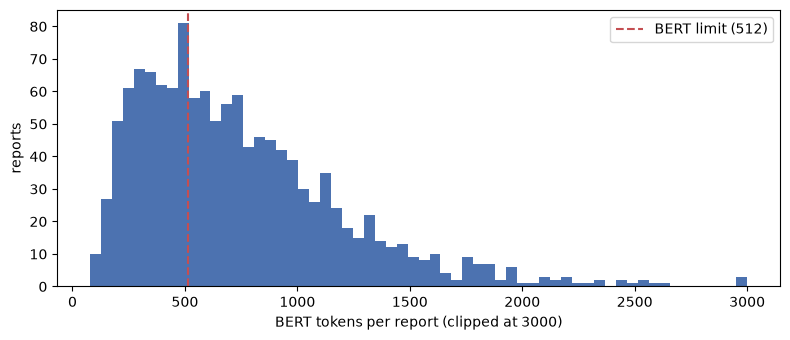

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df["n_tokens"].clip(upper=3000), bins=60, color="#4C72B0")
ax.axvline(max_tokens, color="#C44E52", linestyle="--", label=f"BERT limit ({max_tokens})")
ax.set_xlabel("BERT tokens per report (clipped at 3000)")
ax.set_ylabel("reports")
ax.legend()
plt.tight_layout()

## 5. Operative reports per class

Many MTSamples reports are operative notes with the same structure
(PREOPERATIVE DIAGNOSIS, PROCEDURE, ANESTHESIA, ...). If some specialties are
mostly operative notes and others mostly consults, a model could partly learn
*report type* instead of *specialty*.

Two independent signals:
- **header**: the text contains an operative section header (`is_operative` in `src/data.py`)
- **filed under Surgery**: MTSamples also listed the report under "Surgery" (from the raw labels)

In [10]:
df["operative_header"] = df["text"].map(is_operative)
df["filed_under_surgery"] = df["raw_labels"].str.contains("Surgery", regex=False)
op = df.groupby("label")[["operative_header", "filed_under_surgery"]].mean().mul(100).round(1)
op.columns = ["% operative header", "% filed under Surgery"]
op.loc[CLASS_ORDER]

,% operative header,% filed under Surgery
label,,
Cardiovascular / Pulmonary,31.2,48.0
Orthopedic,58.4,70.3
Gastroenterology,53.3,73.9
Obstetrics / Gynecology,34.3,68.6
Urology,51.1,67.2
Neurology,0.0,0.0
ENT - Otolaryngology,50.6,68.4
Ophthalmology,63.0,78.1


In [11]:
print("Overall:", f"{100 * df['operative_header'].mean():.1f}% have an operative header,",
      f"{100 * df['filed_under_surgery'].mean():.1f}% were filed under Surgery")
print("Agreement between the two signals:")
pd.crosstab(df["operative_header"], df["filed_under_surgery"])

Overall: 41.4% have an operative header, 58.1% were filed under Surgery
Agreement between the two signals:


filed_under_surgery,False,True
operative_header,,
False,531,220
True,6,525


## 6. MACCROBAT entities

After mapping: SYMPTOM ← Sign_symptom, TREATMENT ← Medication + Therapeutic_procedure.

In [12]:
stats = json.loads((PROCESSED_DIR / "maccrobat" / "stats.json").read_text())
pd.DataFrame({
    split: {"documents": stats[f"{split}_docs"], "SYMPTOM": stats[f"{split}_SYMPTOM"], "TREATMENT": stats[f"{split}_TREATMENT"]}
    for split in ["train", "val", "test"]
}).T

,documents,SYMPTOM,TREATMENT
train,140,2414,1483
val,30,535,238
test,30,431,392


In [13]:
print({k: stats[k] for k in ["documents", "discontinuous_skipped", "overlaps_removed"]})
train_docs = load_maccrobat_split("train")
ents = pd.DataFrame([(e.label_, e.text.lower(), len(e)) for d in train_docs for e in d.ents],
                    columns=["label", "text", "n_tokens"])
ents.groupby("label")["n_tokens"].describe()[["mean", "50%", "max"]]

{'documents': 200, 'discontinuous_skipped': 1, 'overlaps_removed': 4}


,mean,50%,max
label,,,
SYMPTOM,1.485501,1.0,13.0
TREATMENT,1.541470,1.0,11.0


In [14]:
# Most frequent entity texts per label (train split)
top = {label: ents[ents["label"] == label]["text"].value_counts().head(15) for label in ["SYMPTOM", "TREATMENT"]}
pd.DataFrame({label: [f"{t} ({n})" for t, n in s.items()] for label, s in top.items()})

,SYMPTOM,TREATMENT
0,mass (89),chemotherapy (35)
1,pain (73),resection (25)
2,dyspnea (41),prednisone (15)
3,tumor (40),surgery (14)
4,lesion (34),treatment (13)
5,lesions (32),antibiotics (13)
6,edema (27),diuretics (11)
7,fever (21),medication (10)
8,tachycardia (21),ablation (10)
9,bleeding (20),steroids (9)


In [15]:
from spacy import displacy

# One annotated example (first sentences of the first training document)
doc = train_docs[0]
displacy.render(doc[:90].as_doc(), style="ent", jupyter=True,
                options={"colors": {"SYMPTOM": "#f4a6a6", "TREATMENT": "#9fd3a8"}})

## Takeaways

**MTSamples**
- Only 1,282 of 4,999 rows survive cleaning. Most removed rows are the same report filed under a second, catch-all label (2,609 duplicates).
- 41 truncated scrapes (< 50 words, e.g. `"INDICATIONS:,"`) were removed. The shortest kept report has 52 words.
- Classes are imbalanced (Cardio 26% vs Ophthalmology 5.7%). We report **macro** F1 so small classes count as much as large ones, and the baseline uses class weights.
- Test set is small (193 reports, 11–12 for ENT and Ophthalmology), so per-class scores for small classes are noisy.

**BERT length limit**
- 62.6% of reports exceed 512 tokens, and truncation cuts 40% of all tokens. BERT only sees the beginning of long reports.
- The beginning usually holds the diagnosis / indication headers, which carry most of the specialty signal, so truncation may hurt less than the 40% suggests. Phase 4 compares plain truncation with head+tail / chunking. The TF-IDF baseline sees the full text.

**Report type vs specialty (possible shortcut)**
- 41% of reports have an operative header and 58% were also filed under "Surgery". The two signals agree on 1,056 / 1,282 reports.
- **Neurology has 0% operative reports**, while every other class has 31–63%. So "this is an operative note" alone rules out Neurology: a model can use report type as a shortcut. We will check this in the evaluation phase (scores on operative vs non-operative test reports).

**MACCROBAT**
- 200 documents, 5,493 entities (3,380 SYMPTOM, 2,113 TREATMENT). Almost nothing was lost in conversion (1 discontinuous span, 4 overlaps).
- Entities are short (median 1 token).
- MACCROBAT's `Sign_symptom` also covers clinical *findings* ("mass", "lesion", "tumor"), so our SYMPTOM label means "signs and symptoms".
- Domain shift: MACCROBAT is published case reports, MTSamples is dictated transcriptions; NER quality on MTSamples will be lower than on the MACCROBAT test set.
